                    accuracy  precision_macro  recall_macro  f1_macro  roc_auc
model                                                                         
v2_mlp                 0.779            0.768         0.776     0.771    0.926
v2_cnn                 0.871            0.905         0.865     0.881    0.974
v2_densenet            0.947            0.957         0.944     0.951    0.993
v1_asama1_mlp          0.821            0.842         0.776     0.792    0.911
v1_asama1_cnn          0.808            0.865         0.748     0.765    0.934
v1_asama1_densenet     0.909            0.927         0.882     0.898    0.978
v1_asama2_mlp          0.849            0.838         0.843     0.840    0.914
v1_asama2_cnn          0.905            0.902         0.896     0.899    0.938
v1_asama2_densenet     0.864            0.854         0.864     0.858    0.943


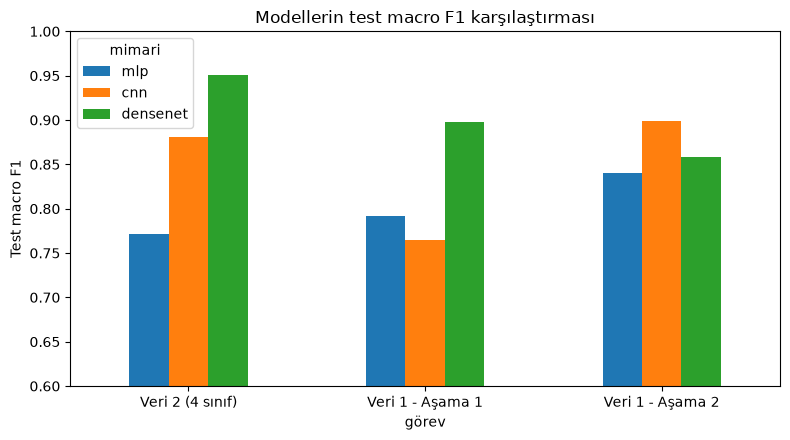

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

klasor = Path("../sonuclar")
adlar = ["v2_mlp", "v2_cnn", "v2_densenet",
         "v1_asama1_mlp", "v1_asama1_cnn", "v1_asama1_densenet",
         "v1_asama2_mlp", "v1_asama2_cnn", "v1_asama2_densenet"]

satirlar = []
for ad in adlar:
    m = json.loads((klasor / f"{ad}_metrik.json").read_text())
    satirlar.append({"model": ad, **m})
tablo = pd.DataFrame(satirlar).set_index("model").round(3)
print(tablo)
tablo.to_csv(klasor / "karsilastirma.csv")

gorev = {"v2": "Veri 2 (4 sınıf)", "v1_asama1": "Veri 1 - Aşama 1", "v1_asama2": "Veri 1 - Aşama 2"}
t = tablo.reset_index()
t["görev"] = t["model"].apply(lambda a: gorev[a.rsplit("_", 1)[0]])
t["mimari"] = t["model"].apply(lambda a: a.rsplit("_", 1)[1])
pivot = t.pivot(index="görev", columns="mimari", values="f1_macro")[["mlp", "cnn", "densenet"]]
pivot = pivot.loc[list(gorev.values())]

pivot.plot(kind="bar", figsize=(8, 4.5))
plt.ylim(0.6, 1.0)
plt.ylabel("Test macro F1")
plt.title("Modellerin test macro F1 karşılaştırması")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(klasor / "karsilastirma_f1.png", dpi=150)
plt.show()

In [2]:
satirlar = []
for ad in adlar:
    g = pd.read_csv(klasor / f"{ad}_gecmis.csv")
    en_iyi = g.loc[g["dog_f1"].idxmax()]
    satirlar.append({"model": ad, "çalışan epoch": len(g), "en iyi epoch": int(en_iyi["epoch"]),
                     "en iyi doğrulama F1": round(en_iyi["dog_f1"], 3),
                     "son eğitim kaybı": round(g["egitim_kaybi"].iloc[-1], 3)})
ozet = pd.DataFrame(satirlar).set_index("model")
print(ozet)
ozet.to_csv(klasor / "egitim_ozeti.csv")

                    çalışan epoch  en iyi epoch  en iyi doğrulama F1  \
model                                                                  
v2_mlp                         20            18                0.774   
v2_cnn                         19            14                0.885   
v2_densenet                    17            12                0.959   
v1_asama1_mlp                  15            10                0.933   
v1_asama1_cnn                  17            12                0.957   
v1_asama1_densenet              8             3                0.973   
v1_asama2_mlp                  15            10                0.730   
v1_asama2_cnn                  12             7                0.730   
v1_asama2_densenet             13             8                0.764   

                    son eğitim kaybı  
model                                 
v2_mlp                         0.585  
v2_cnn                         0.372  
v2_densenet                    0.040  
v1_asama1_ml